# 04 · Model training and validation

This notebook trains the classical ML models from the brief (**Elastic Net, Random Forest and XGBoost**, plus a mean-prediction baseline), and answers three design questions with controlled experiments:

1. **Target:** should RUL be capped, and at what value? (section 2)
2. **Features:** do the engineered degradation features beat raw sensor readings, and which groups matter? (sections 3 and 4)
3. **Hyperparameters:** how much does tuning help? (section 5)

The official test set is **not touched here**. All decisions are made with cross-validation on the 100 training engines, and the test set is used once, in notebook 05.

In [1]:
import sys
from pathlib import Path

# Make the project folder importable (works from notebooks/ locally and on Colab)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import json
import time

from src.config import RUL_CAP, N_FOLDS, SEED, RESULTS_DIR
from src.data import load_cmapss, add_train_rul
from src.evaluation import rmse, mae, nasa_score
from src.models import (MODEL_NAMES, DEFAULT_PARAMS, build_cv_folds, cross_validate,
                        random_search)
from src.plotting import set_style, save, MODEL_COLORS, BLUE, ORANGE, AQUA, GREY, INK

set_style()
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

train, _, _ = load_cmapss("FD001")
train = add_train_rul(train)

## 1. Validation protocol

**Split by engine, never by row.** Consecutive cycles of one engine are almost identical. If rows of the same engine landed in both the training and validation parts, the model would be validated on near-copies of what it had seen, and the score would be far too optimistic. We therefore use **5-fold cross-validation over engine ids**: each fold holds out 20 complete engines.

**Features are rebuilt inside each fold.** `build_cv_folds` fits the `FeatureBuilder` (normalisation statistics and PCA health index) on the 80 training engines of each fold only, then applies it to the 20 held-out engines.

**Metrics.** With $d_j = \hat y_j - y_j$ (predicted minus true):

$$\text{RMSE} = \sqrt{\tfrac{1}{n}\textstyle\sum_j d_j^2} \qquad \text{MAE} = \tfrac{1}{n}\textstyle\sum_j |d_j| \qquad S = \sum_j \begin{cases} e^{-d_j/13} - 1 & d_j < 0 \\ e^{d_j/10} - 1 & d_j \ge 0 \end{cases}$$

RMSE is the main metric. The NASA score $S$ from the PHM08 challenge (Saxena et al., 2008) penalises late predictions (over-estimating the remaining life) more than early ones, because in maintenance those are the dangerous errors. We report it as a mean per prediction. Unless stated otherwise, CV errors are computed on **all cycles** of the held-out engines against the **capped** target, the quantity the models are trained to predict.

In [2]:
t0 = time.time()
folds, groups = build_cv_folds(train, n_folds=N_FOLDS, seed=SEED)
ALL = [c for cols in groups.values() for c in cols]
RAW = groups["sensors"]

pd.DataFrame([{"fold": i + 1, "validation engines": len(np.unique(f["units_va"])),
               "train rows": len(f["X_tr"]), "validation rows": len(f["X_va"])}
              for i, f in enumerate(folds)]).set_index("fold").T

fold,1,2,3,4,5
validation engines,20,20,20,20,20
train rows,16779,16767,16037,16414,16527
validation rows,3852,3864,4594,4217,4104


## 2. Target design: linear versus piecewise-linear RUL

Notebook 02 suggested capping RUL at around 125 to 150 cycles. We test this directly by training XGBoost (default settings, all features) with no cap and with caps from 100 to 175.

Comparing caps needs care, because each model predicts a different target. We therefore score all of them against the **true, uncapped RUL**, in two regions:

- **RUL ≤ 150 (decision region):** the last 150 cycles, where a maintenance decision actually depends on the prediction. Whether an engine has 250 or 300 cycles left rarely changes what an operator does.
- **All cycles:** the full life, including the healthy phase.

In [3]:
caps = [None, 100, 115, 125, 140, 155, 175]
rows = []
for cap in caps:
    _, oof = cross_validate("xgboost", folds, ALL, cap=cap, return_oof=True)
    near = oof["true_rul"] <= 150
    rows.append({"cap": "none (linear)" if cap is None else cap,
                 "RMSE, RUL <= 150": rmse(oof.loc[near, "true_rul"], oof.loc[near, "pred"]),
                 "MAE, RUL <= 150": mae(oof.loc[near, "true_rul"], oof.loc[near, "pred"]),
                 "RMSE, all cycles": rmse(oof["true_rul"], oof["pred"])})
cap_results = pd.DataFrame(rows).set_index("cap")
cap_results.round(2)

,"RMSE, RUL <= 150","MAE, RUL <= 150","RMSE, all cycles"
cap,,,
none (linear),23.42,15.00,36.46
100,18.77,12.76,56.87
115,14.44,10.16,49.52
125,13.17,9.37,45.43
140,13.28,9.30,40.64
155,14.66,10.12,37.18
175,16.91,11.57,34.85


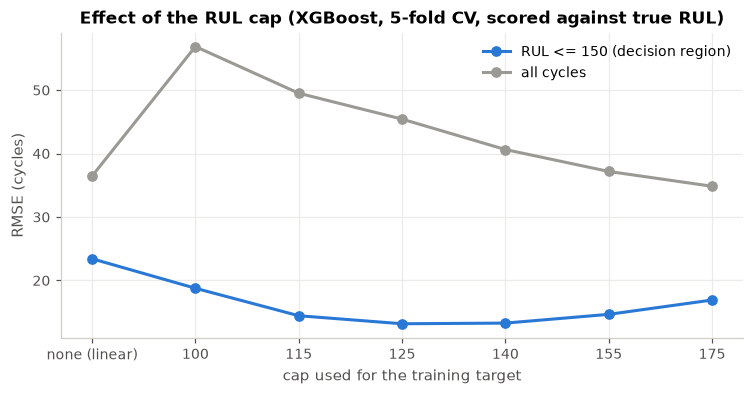

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.6))
labels = [str(c) for c in cap_results.index]
ax.plot(labels, cap_results["RMSE, RUL <= 150"], marker="o", color=BLUE, label="RUL <= 150 (decision region)")
ax.plot(labels, cap_results["RMSE, all cycles"], marker="o", color=GREY, label="all cycles")
ax.set(title="Effect of the RUL cap (XGBoost, 5-fold CV, scored against true RUL)",
       xlabel="cap used for the training target", ylabel="RMSE (cycles)")
ax.legend()
save(fig, "04_target_cap")
plt.show()

- The **linear target** (no cap) is clearly worst in the decision region: RMSE 23.4 against 13.2 for cap 125. Trying to predict exact RUL for healthy engines adds noise that hurts the predictions that matter.
- The error is lowest for caps of **125 to 140** (13.2 and 13.3, practically a tie). Lower caps (100, 115) cannot represent engines with 100+ cycles left; higher caps (155, 175) bring back the noise of the healthy phase.
- Over *all* cycles, the linear target looks better, simply because it is the only one allowed to predict values above the cap. That is the expected trade-off, and it is why the decision region is the relevant view.

**Decision:** cap at **125** cycles. It has the best decision-region RMSE, it is consistent with the onset analysis in notebook 02, and it is the value most C-MAPSS papers use, which keeps our numbers comparable.

## 3. Model comparison: raw sensors versus engineered features

This is the core comparison of Phase 1. Every model is trained twice, once on the **14 raw (normalised) sensor readings** and once on **all 88 engineered features**, with default hyperparameters so that neither side benefits from extra tuning.

In [5]:
rows, fold_scores = [], {}
for name in ["mean", "elastic_net", "random_forest", "xgboost"]:
    for fs_name, fs in [("raw sensors", RAW), ("engineered", ALL)]:
        if name == "mean" and fs_name == "engineered":
            continue                                   # the mean baseline ignores features
        start = time.time()
        scores, oof = cross_validate(name, folds, fs, return_oof=True)
        y_cap = oof["true_rul"].clip(upper=RUL_CAP)
        rows.append({"model": MODEL_NAMES[name], "features": fs_name, "n features": len(fs),
                     "CV RMSE": scores.mean(), "± std (folds)": scores.std(),
                     "CV MAE": mae(y_cap, oof["pred"]), "NASA score (mean)": nasa_score(y_cap, oof["pred"]) / len(oof),
                     "time (s)": time.time() - start})
        fold_scores[(MODEL_NAMES[name], fs_name)] = scores
comparison = pd.DataFrame(rows)
comparison.round(2)

,model,features,n features,CV RMSE,± std (folds),CV MAE,NASA score (mean),time (s)
0,Mean baseline,raw sensors,14,41.73,0.20,37.01,308.40,0.02
1,Elastic Net,raw sensors,14,21.28,0.54,17.34,9.14,0.06
2,Elastic Net,engineered,88,15.62,1.52,12.69,3.92,2.80
3,Random Forest,raw sensors,14,18.43,0.61,13.56,12.54,3.36
4,Random Forest,engineered,88,10.48,1.13,7.03,1.79,27.58
5,XGBoost,raw sensors,14,18.57,0.53,13.49,13.43,1.50
6,XGBoost,engineered,88,9.48,0.62,6.30,1.46,3.85


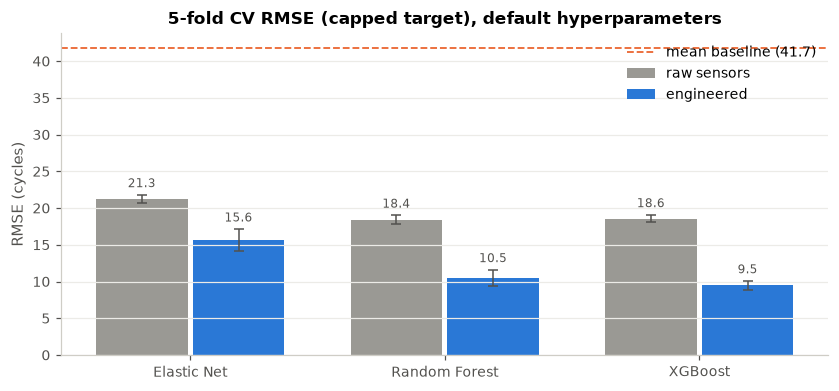

In [6]:
fig, ax = plt.subplots(figsize=(9, 3.8))
models = ["Elastic Net", "Random Forest", "XGBoost"]
x = np.arange(len(models))
for k, (fs_name, color) in enumerate([("raw sensors", GREY), ("engineered", BLUE)]):
    sub = comparison[comparison["features"] == fs_name].set_index("model").loc[models]
    bars = ax.bar(x + (k - 0.5) * 0.38, sub["CV RMSE"], 0.36, yerr=sub["± std (folds)"],
                  color=color, label=fs_name, capsize=3, error_kw={"ecolor": INK, "lw": 1})
    ax.bar_label(bars, fmt="%.1f", padding=3, fontsize=8, color=INK)
baseline = comparison.loc[comparison["model"] == "Mean baseline", "CV RMSE"].iloc[0]
ax.axhline(baseline, color=ORANGE, ls="--", lw=1.2, label=f"mean baseline ({baseline:.1f})")
ax.set_xticks(x, models)
ax.set(title="5-fold CV RMSE (capped target), default hyperparameters", ylabel="RMSE (cycles)")
ax.legend(loc="upper right")
ax.grid(axis="x", visible=False)
save(fig, "04_model_comparison")
plt.show()

**Engineered features roughly halve the error.** With the same model and default settings:

| Model | raw sensors | engineered | improvement |
|---|---|---|---|
| Elastic Net | 21.3 | 15.6 | −27% |
| Random Forest | 18.4 | 10.5 | −43% |
| XGBoost | 18.6 | 9.5 | −49% |

- Every model beats the mean baseline (41.7) by a wide margin.
- On **raw sensors**, all three models are limited by the noise in a single reading. Random Forest and XGBoost are almost identical, so the bottleneck is the input, not the model.
- On **engineered features**, the tree models gain the most because they can combine levels, slopes and baselines non-linearly. XGBoost is best, with the lowest error and the smallest variation between folds.
- **Elastic Net** improves too but stays well behind. A linear function of the features cannot express the piecewise-linear target: a flat region at 125 followed by a decline.
- The NASA score follows the same ranking, so the improvement is not bought with more dangerous late predictions.

## 4. Ablation: which feature groups matter?

Two complementary views, using XGBoost and Elastic Net with default settings:

- **Forward:** start from raw sensors and add one group at a time, in the order of the table in notebook 03.
- **Leave one group out:** start from the full set and remove one group at a time. A large increase in error means the group carries information that no other group provides.

In [7]:
order = ["sensors", "cycle", "rolling", "slope", "baseline_dev", "health"]
forward, current = [], []
for g in order:
    current = current + groups[g]
    row = {"feature set": ("+ " if g != "sensors" else "") + g, "n features": len(current)}
    for name in ["elastic_net", "xgboost"]:
        row[MODEL_NAMES[name]] = cross_validate(name, folds, current).mean()
    forward.append(row)
forward = pd.DataFrame(forward).set_index("feature set")

loo = []
for g in order:
    kept = [c for c in ALL if c not in groups[g]]
    row = {"removed group": g}
    for name in ["elastic_net", "xgboost"]:
        row[MODEL_NAMES[name]] = cross_validate(name, folds, kept).mean()
    loo.append(row)
loo = pd.DataFrame(loo).set_index("removed group")
full_scores = {MODEL_NAMES[n]: cross_validate(n, folds, ALL).mean() for n in ["elastic_net", "xgboost"]}
loo_delta = loo - pd.Series(full_scores)

display(forward.round(2))
display(loo_delta.round(2).rename(columns=lambda c: f"{c}: RMSE change"))

,n features,Elastic Net,XGBoost
feature set,,,
sensors,14,21.28,18.57
+ cycle,15,20.35,16.92
+ rolling,43,20.32,17.23
+ slope,71,15.86,11.96
+ baseline_dev,85,15.62,9.66
+ health,88,15.62,9.48


,Elastic Net: RMSE change,XGBoost: RMSE change
removed group,,
sensors,-0.01,0.01
cycle,-0.31,2.11
rolling,-0.01,-0.23
slope,0.12,0.00
baseline_dev,0.24,1.85
health,0.00,0.18


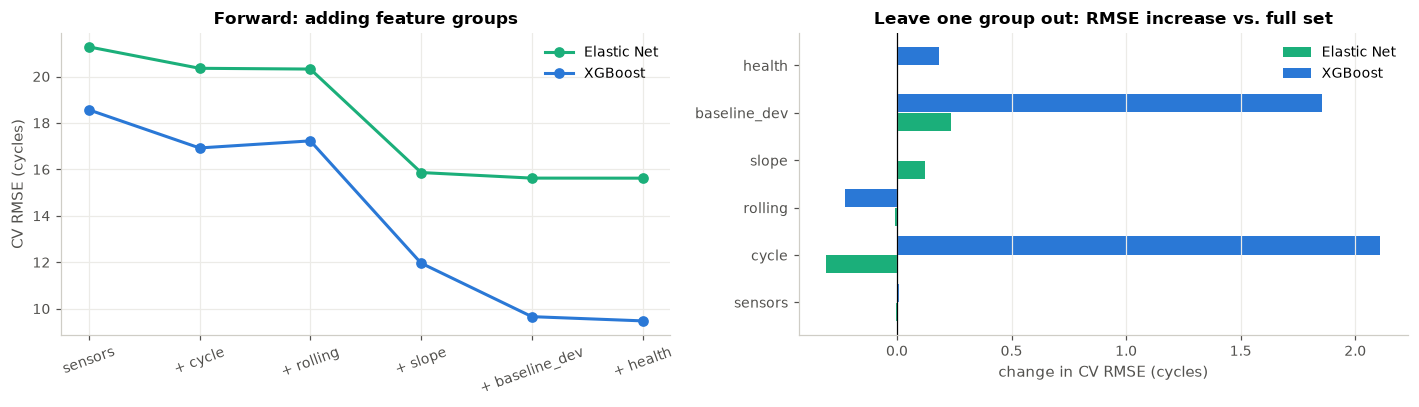

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for name, color in [("Elastic Net", AQUA), ("XGBoost", BLUE)]:
    axes[0].plot(forward.index, forward[name], marker="o", color=color, label=name)
axes[0].set(title="Forward: adding feature groups", ylabel="CV RMSE (cycles)")
axes[0].tick_params(axis="x", rotation=20)
axes[0].legend()

y = np.arange(len(loo_delta))
axes[1].barh(y - 0.2, loo_delta["Elastic Net"], 0.38, color=AQUA, label="Elastic Net")
axes[1].barh(y + 0.2, loo_delta["XGBoost"], 0.38, color=BLUE, label="XGBoost")
axes[1].set_yticks(y, loo_delta.index)
axes[1].axvline(0, color="black", lw=0.8)
axes[1].set(title="Leave one group out: RMSE increase vs. full set", xlabel="change in CV RMSE (cycles)")
axes[1].grid(axis="y", visible=False)
axes[1].legend()
fig.tight_layout()
save(fig, "04_feature_ablation")
plt.show()

**Forward view (XGBoost):**
- Adding `cycle` helps (18.6 → 16.9): age is a useful prior.
- Rolling mean/std alone add little on top of that (17.2). A smoothed level is still a level, and it does not tell the model how far this particular engine has moved.
- **Slopes** give the biggest single jump (→ 12.0). Knowing *how fast* the sensors are changing is what separates a degrading engine from a healthy one.
- **Baseline deviation** brings another large gain (→ 9.7). Comparing each engine with its own early-life state removes the engine-to-engine offset.
- The **health index** adds a final small improvement (→ 9.5).

**Leave-one-group-out view (XGBoost):**
- Removing `cycle` (+2.1) or `baseline_dev` (+1.9) hurts most. They contain information no other group provides.
- Removing slopes changes nothing (0.0) even though slopes helped a lot in the forward view. Their information overlaps with the baseline deviations and the health-index slope: once the model knows how far an engine has drifted since cycle 1, the recent slope adds little.
- Removing the rolling mean/std slightly *improves* the score (−0.2), so this group is redundant given the others.

For **Elastic Net** the differences are small (within ±0.3) once the slopes are in. The linear model is limited by its functional form rather than by the features.

*Takeaway:* the most valuable engineered information is the change relative to the engine's own history (slopes and baseline deviation), plus the cycle count as a prior. This is the "degradation feature" logic the brief asks for.

## 5. Hyperparameter tuning

We tune each model with **random search** over the ranges below, scored by mean 5-fold CV RMSE on the engineered features. Random search covers wide ranges more efficiently than a grid when only a few hyperparameters matter (Bergstra & Bengio, 2012).

| Model | Hyperparameters searched |
|---|---|
| Elastic Net | `alpha` (overall penalty strength, log scale 0.01-10), `l1_ratio` (mix between L1 and L2, 0.05-1) |
| Random Forest | number of trees, `max_depth`, `min_samples_leaf`, `max_features` (share of features tried per split) |
| XGBoost | number of trees, `learning_rate`, `max_depth`, `min_child_weight`, `subsample`, `colsample_bytree`, `reg_lambda` |

The validation folds are used for model selection here, so the tuned CV scores are slightly optimistic. The unbiased estimate comes from the untouched test set in notebook 05.

In [9]:
n_iter = {"elastic_net": 20, "random_forest": 10, "xgboost": 30}
searches, best_params = {}, {}
for name, n in n_iter.items():
    start = time.time()
    searches[name] = random_search(name, folds, ALL, n_iter=n, seed=SEED)
    best = searches[name].iloc[0]
    best_params[name] = {k: (None if pd.isna(v) else (int(v) if float(v).is_integer() and k != "alpha" else float(v)))
                         for k, v in best.drop(["cv_rmse", "cv_std"]).items()}
    print(f"{MODEL_NAMES[name]:<14} {n} candidates in {time.time() - start:5.0f}s  ->  best CV RMSE {best['cv_rmse']:.2f}")

with open(RESULTS_DIR / "best_params.json", "w") as f:
    json.dump(best_params, f, indent=2)
pd.DataFrame(best_params).T

Elastic Net    20 candidates in    66s  ->  best CV RMSE 15.41


Random Forest  10 candidates in   185s  ->  best CV RMSE 10.51


XGBoost        30 candidates in   132s  ->  best CV RMSE 9.26


,alpha,l1_ratio,max_depth,max_features,min_samples_leaf,n_estimators,colsample_bytree,learning_rate,min_child_weight,reg_lambda,subsample
elastic_net,0.598747,0.094128,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
random_forest,NaN,NaN,16.0,0.459195,7.0,250.0,NaN,NaN,NaN,NaN,NaN
xgboost,NaN,NaN,3.0,NaN,NaN,760.0,0.805414,0.090477,10.0,0.335661,0.669982


In [10]:
searches["xgboost"].head(5).round(3)

,colsample_bytree,learning_rate,max_depth,min_child_weight,n_estimators,reg_lambda,subsample,cv_rmse,cv_std
0,0.805,0.090,3,10,760,0.336,0.670,9.262,0.505
1,0.691,0.080,3,12,523,0.319,0.823,9.288,0.564
2,0.827,0.107,4,5,639,0.668,0.646,9.406,0.581
3,0.545,0.075,4,17,443,0.702,0.853,9.407,0.589
4,0.629,0.190,2,3,634,2.500,0.668,9.430,0.353


### 5.1 Tuned models, fold by fold

In [11]:
rows, oof_all = [], []
for name in ["elastic_net", "random_forest", "xgboost"]:
    default = cross_validate(name, folds, ALL)
    tuned, oof = cross_validate(name, folds, ALL, params=best_params[name], return_oof=True)
    fold_scores[(MODEL_NAMES[name], "tuned")] = tuned
    y_cap = oof["true_rul"].clip(upper=RUL_CAP)
    rows.append({"model": MODEL_NAMES[name], "default CV RMSE": default.mean(),
                 "tuned CV RMSE": tuned.mean(), "± std": tuned.std(),
                 "tuned CV MAE": mae(y_cap, oof["pred"]),
                 "NASA score (mean)": nasa_score(y_cap, oof["pred"]) / len(oof)})
    oof_all.append(oof.assign(model=MODEL_NAMES[name]))
tuned_table = pd.DataFrame(rows).set_index("model")
oof_all = pd.concat(oof_all, ignore_index=True)
oof_all.to_csv(RESULTS_DIR / "cv_oof_predictions.csv", index=False)
tuned_table.round(2)

,default CV RMSE,tuned CV RMSE,± std,tuned CV MAE,NASA score (mean)
model,,,,,
Elastic Net,15.62,15.41,1.04,12.6,3.76
Random Forest,10.48,10.51,1.05,7.0,1.82
XGBoost,9.48,9.26,0.50,6.3,1.39


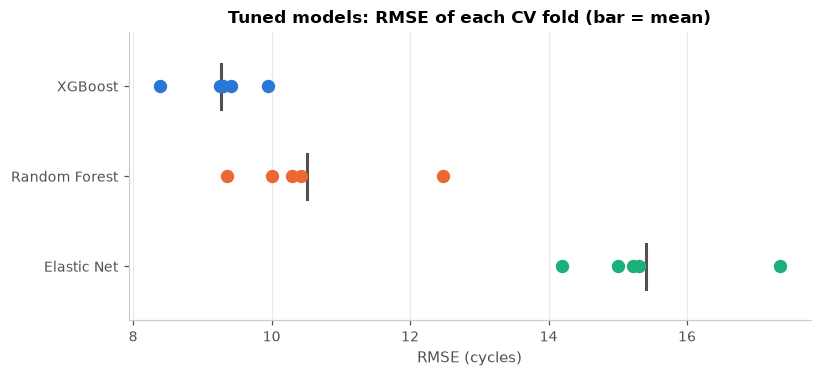

XGBoost beats Random Forest on 5 of 5 folds (mean difference 1.25 cycles)


In [12]:
fig, ax = plt.subplots(figsize=(8, 3.4))
for i, name in enumerate(["Elastic Net", "Random Forest", "XGBoost"]):
    s = fold_scores[(name, "tuned")]
    ax.scatter(s, np.full(len(s), i), color=MODEL_COLORS[name], s=60, zorder=3)
    ax.plot([s.mean()] * 2, [i - 0.25, i + 0.25], color=INK, lw=2)
ax.set_yticks(range(3), ["Elastic Net", "Random Forest", "XGBoost"])
ax.set(title="Tuned models: RMSE of each CV fold (bar = mean)", xlabel="RMSE (cycles)", ylim=(-0.6, 2.6))
ax.grid(axis="y", visible=False)
save(fig, "04_cv_folds")
plt.show()

xgb, rf = fold_scores[("XGBoost", "tuned")], fold_scores[("Random Forest", "tuned")]
print(f"XGBoost beats Random Forest on {(xgb < rf).sum()} of {len(xgb)} folds "
      f"(mean difference {np.mean(rf - xgb):.2f} cycles)")

- Tuning gives only small improvements: XGBoost 9.48 → **9.26**, Elastic Net 15.62 → 15.41. Random Forest stays at about 10.5: the best of 10 random candidates is no better than the defaults, which is typical for random forests and within fold-to-fold noise. The default settings were already reasonable, and **feature engineering matters far more than hyperparameter tuning** here (about 9 cycles of RMSE versus about 0.2).
- The best XGBoost configurations use **shallow trees** (depth 3), many boosting rounds, row subsampling and a minimum child weight of about 10, all of which regularise the model.
- **XGBoost beats Random Forest on all 5 folds**, by 1.25 cycles on average, so the ranking is consistent and not the result of a single lucky split.
- The fold-to-fold standard deviation (about 0.5 for XGBoost, 1.0 for the others) is a reminder that with only 20 engines per fold, differences below about 0.5 cycles should not be over-interpreted.

In [13]:
summary = comparison.copy()
summary.to_csv(RESULTS_DIR / "cv_model_comparison.csv", index=False)
forward.to_csv(RESULTS_DIR / "cv_ablation_forward.csv")
loo_delta.to_csv(RESULTS_DIR / "cv_ablation_leave_one_out.csv")
cap_results.to_csv(RESULTS_DIR / "cv_target_cap.csv")
tuned_table.to_csv(RESULTS_DIR / "cv_tuned_models.csv")
print(f"total run time: {(time.time() - t0) / 60:.1f} min")

total run time: 9.9 min


## Summary

| Question | Answer from cross-validation |
|---|---|
| Cap the target? | Yes. A cap of 125 cuts decision-region RMSE from 23.4 (linear) to 13.2 |
| Do engineered features help? | Yes, a lot. RMSE roughly halves for the tree models (XGBoost 18.6 → 9.5) |
| Which features matter? | change relative to the engine's own history (baseline deviation, slopes) and cycle |
| Which model? | XGBoost (tuned CV RMSE 9.26 ± 0.50), ahead of Random Forest on every fold |
| Does tuning matter? | only slightly (about 0.2 cycles) |

The tuned hyperparameters are saved in `outputs/results/best_params.json`, and the out-of-fold predictions in `outputs/results/cv_oof_predictions.csv`. Notebook 05 uses them to evaluate on the official test set.